# One-Shot PatchCore with a WRN-50 + DINOv2 Fusion Backbone
CS3807 Deep Learning Laboratory mini-project, Shiv Nadar University Chennai.

Extends PatchCore (Roth et al., CVPR 2022) in the **one-shot** setting on **MVTec AD**, using the paper's
PatchCore-10 configuration (10% greedy coreset, 224×224 input). Compares the paper's WRN-50 backbone,
DINOv2 ViT-S/14, and a fusion of both, on identical training images for 10 seeds × 15 categories.

Code: https://github.com/cheriian/oneshot-fusion-patchcore

**Runtime:** Google Colab, Python 3, T4 GPU. Results are appended to `results.csv` on Google Drive; every run
cell is resumable and skips (category, seed, method) combinations that are already recorded.

## 1. Setup
Mount Google Drive (results are stored there), download MVTec AD from the official MVTec link,
and clone the official PatchCore implementation, whose feature extractor, coreset sampler and metrics are reused unchanged.

In [22]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
!mkdir -p /content/drive/MyDrive/DL_Project

Mounted at /content/drive


In [23]:
!wget -O /content/mvtec.tar.xz "https://www.mydrive.ch/shares/163178/c8212c2166a9e4dfe22dd1bed476a345/download/420938113-1629960298/mvtec_anomaly_detection.tar.xz"
!mkdir -p /content/mvtec && tar -xf /content/mvtec.tar.xz -C /content/mvtec
!ls /content/mvtec

--2026-11-03 14:46:59--  https://www.mydrive.ch/shares/163178/c8212c2166a9e4dfe22dd1bed476a345/download/420938113-1629960298/mvtec_anomaly_detection.tar.xz
Resolving www.mydrive.ch (www.mydrive.ch)... 91.213.4.64
Connecting to www.mydrive.ch (www.mydrive.ch)|91.213.4.64|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5264982680 (4.9G) [application/x-xz]
Saving to: ‘/content/mvtec.tar.xz’

/content/mvtec.tar. 100%[===================>]   4.90G  19.8MB/s    in 4m 11s  

2026-11-03 14:51:12 (20.0 MB/s) - ‘/content/mvtec.tar.xz’ saved [5264982680/5264982680]

bottle	 carpet    leather	pill	    tile	wood
cable	 grid	   license.txt	readme.txt  toothbrush	zipper
capsule  hazelnut  metal_nut	screw	    transistor


In [24]:
%cd /content
!git clone https://github.com/amazon-research/patchcore-inspection.git
%cd /content/patchcore-inspection
!pip install faiss-cpu pretrainedmodels timm

/content
fatal: destination path 'patchcore-inspection' already exists and is not an empty directory.
/content/patchcore-inspection


## 2. Experiment script
`oneshot_patchcore.py` runs one-shot PatchCore with one of three backbones:
- `wrn50`: the paper's baseline, run entirely through the official `PatchCore` class (layers 2+3).
- `dinov2`: DINOv2 ViT-S/14 patch tokens (blocks 7 and 11) on their native 16×16 grid.
- `fusion`: WRN-50 and DINOv2 features, L2-normalised, DINOv2 upsampled to 28×28, concatenated with weight `--alpha` on WRN-50.

For a given seed, every backbone uses the same training image, so comparisons between backbones are paired.

In [ ]:
%%writefile /content/drive/MyDrive/DL_Project/oneshot_patchcore.py
"""One-shot PatchCore on MVTec AD: WRN-50 (paper) vs DINOv2 vs WRN-50 + DINOv2 feature fusion.
Same images, resolution, coreset (10%), scoring and seeds for every backbone."""
import argparse, csv, os, random, time
import numpy as np
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from torch.utils.data import DataLoader, Subset

import patchcore.backbones
import patchcore.common
import patchcore.metrics
import patchcore.patchcore
import patchcore.sampler
from patchcore.datasets.mvtec import DatasetSplit, MVTecDataset

CLASSES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather",
           "metal_nut", "pill", "screw", "tile", "toothbrush", "transistor", "wood", "zipper"]
FIELDS = ["classname", "shots", "seed", "method", "n_train", "img_auroc", "pix_auroc", "sec_per_img"]


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def build_wrn(imagesize, coreset, device):
    backbone = patchcore.backbones.load("wideresnet50")
    backbone.name, backbone.seed = "wideresnet50", None
    model = patchcore.patchcore.PatchCore(device)
    model.load(backbone=backbone, layers_to_extract_from=["layer2", "layer3"], device=device,
               input_shape=(3, imagesize, imagesize), pretrain_embed_dimension=1024,
               target_embed_dimension=1024, patchsize=3,
               featuresampler=patchcore.sampler.ApproximateGreedyCoresetSampler(coreset, device),
               nn_method=patchcore.common.FaissNN(False, 4))
    return model


# ---------- Baseline: official PatchCore, WRN-50 layers 2+3 (unchanged from pilot) ----------
def run_wrn(train_ds, test_loader, imagesize, coreset, device):
    model = build_wrn(imagesize, coreset, device)
    model.fit(DataLoader(train_ds, batch_size=8, shuffle=False, num_workers=2))
    t0 = time.time()
    scores, segs, labels, masks = model.predict(test_loader)
    sec = (time.time() - t0) / len(test_loader.dataset)
    return np.array(scores), np.array(segs), np.array(labels), np.array(masks), sec


# ---------- DINOv2 patch tokens (unchanged from pilot) ----------
class DinoFeatures:
    def __init__(self, arch, layers, device):
        self.model = torch.hub.load("facebookresearch/dinov2", arch, trust_repo=True).to(device).eval()
        self.layers, self.device = layers, device

    @torch.no_grad()
    def __call__(self, x):
        feats = self.model.get_intermediate_layers(x.to(self.device), n=self.layers, reshape=True)
        feats = [F.avg_pool2d(f, 3, stride=1, padding=1) for f in feats]  # PatchCore p=3 neighbourhood
        return torch.cat(feats, dim=1)  # B x C x h x w


# ---------- Extension: WRN-50 + DINOv2 fused per patch ----------
class FusionFeatures:
    """WRN-50 patch features exactly as PatchCore builds them (layer2+3, p=3, 1024-d, 28x28 at 224px)
    + DINOv2 tokens upsampled to the same grid. Each branch is L2-normalised and weighted so that
    ||f-f'||^2 = alpha*||w-w'||^2 + (1-alpha)*||d-d'||^2."""
    def __init__(self, arch, layers, imagesize, coreset, alpha, device):
        self.dino = DinoFeatures(arch, layers, device)
        self.wrn = build_wrn(imagesize, coreset, device)  # only its feature extractor is used
        self.a_w, self.a_d = alpha ** 0.5, (1.0 - alpha) ** 0.5
        self.device = device

    @torch.no_grad()
    def __call__(self, x):
        x = x.to(self.device, dtype=torch.float)
        w, shapes = self.wrn._embed(x, detach=False, provide_patch_shapes=True)  # official PatchCore features
        if isinstance(w, (list, tuple)):
            w = torch.stack([torch.as_tensor(v) for v in w])
        w = torch.as_tensor(w, device=self.device, dtype=torch.float)
        (hh, ww), B = shapes[0], x.shape[0]
        assert w.shape[0] == B * hh * ww, f"unexpected WRN feature shape {tuple(w.shape)}"
        w = w.reshape(B, hh, ww, -1).permute(0, 3, 1, 2)                     # B x 1024 x 28 x 28
        d = F.interpolate(self.dino(x), size=(hh, ww), mode="bilinear", align_corners=False)
        return torch.cat([self.a_w * F.normalize(w, dim=1), self.a_d * F.normalize(d, dim=1)], dim=1)


def to_patches(f):  # B x C x h x w -> (B*h*w) x C
    return f.permute(0, 2, 3, 1).reshape(-1, f.shape[1])


@torch.no_grad()
def nn_dist(q, bank, chunk=2048):  # distance of each test patch to nearest memory-bank patch
    return torch.cat([torch.cdist(c, bank).min(dim=1).values for c in q.split(chunk)])


@torch.no_grad()
def run_bank(extractor, train_ds, test_loader, imagesize, coreset, device):
    """Memory-bank PatchCore for any extractor returning B x C x h x w (DINOv2 or Fusion)."""
    loader = DataLoader(train_ds, batch_size=8, shuffle=False, num_workers=2)
    feats = torch.cat([to_patches(extractor(b["image"])).cpu() for b in loader]).numpy()
    sampler = patchcore.sampler.ApproximateGreedyCoresetSampler(coreset, device)  # official greedy coreset
    bank = torch.as_tensor(np.asarray(sampler.run(feats)), device=device)
    t0 = time.time()
    scores, maps, labels, masks = [], [], [], []
    for b in test_loader:
        f = extractor(b["image"])
        B, C, h, w = f.shape
        d = nn_dist(to_patches(f), bank).reshape(B, 1, h, w)
        scores += d.flatten(1).max(dim=1).values.cpu().tolist()          # image score = worst patch
        up = F.interpolate(d, size=(imagesize, imagesize), mode="bilinear", align_corners=False)
        maps += [gaussian_filter(m, sigma=4) for m in up[:, 0].cpu().numpy()]  # same smoothing as paper
        labels += b["is_anomaly"].tolist()
        masks.append(b["mask"].numpy())
    sec = (time.time() - t0) / len(test_loader.dataset)
    return np.array(scores), np.stack(maps), np.array(labels), np.concatenate(masks), sec


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--data", required=True)
    p.add_argument("--out", default="results.csv")
    p.add_argument("--backbone", choices=["wrn50", "dinov2", "fusion"], required=True)
    p.add_argument("--arch", default="dinov2_vits14")
    p.add_argument("--layers", nargs="+", type=int, default=[7, 11])
    p.add_argument("--alpha", type=float, default=0.5)                # fusion weight on WRN-50
    p.add_argument("--imagesize", type=int, default=224)
    p.add_argument("--classes", nargs="+", default=CLASSES)
    p.add_argument("--shots", nargs="+", type=int, default=[1])       # 0 = full training set
    p.add_argument("--seeds", nargs="+", type=int, default=list(range(10)))
    p.add_argument("--coreset", type=float, default=0.1)              # PatchCore-10
    a = p.parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    size = a.imagesize
    tag = f"{a.arch}_L{'-'.join(map(str, a.layers))}"
    if a.backbone == "wrn50":
        method, extractor = f"wrn50_L2-3_{size}", None
    else:
        assert size % 14 == 0, "image size must be a multiple of 14 for DINOv2 (e.g. 224)"
        if a.backbone == "dinov2":
            method, extractor = f"{tag}_{size}", DinoFeatures(a.arch, a.layers, device)
        else:
            method = f"fusion_wrn50L2-3_{tag}_a{a.alpha:g}_{size}"
            extractor = FusionFeatures(a.arch, a.layers, size, a.coreset, a.alpha, device)
    resize = int(round(size * 256 / 224))  # paper: resize 256, centre-crop 224

    done = set()
    if os.path.exists(a.out):
        with open(a.out) as f:
            done = {(r["classname"], r["shots"], r["seed"], r["method"]) for r in csv.DictReader(f)}
    new_file = not os.path.exists(a.out)
    out = open(a.out, "a", newline="")
    w = csv.DictWriter(out, fieldnames=FIELDS)
    if new_file:
        w.writeheader()

    for cls in a.classes:
        train_full = MVTecDataset(a.data, classname=cls, resize=resize, imagesize=size, split=DatasetSplit.TRAIN)
        test_ds = MVTecDataset(a.data, classname=cls, resize=resize, imagesize=size, split=DatasetSplit.TEST)
        test_loader = DataLoader(test_ds, batch_size=8, shuffle=False, num_workers=2)
        for shots in a.shots:
            for seed in (a.seeds if shots > 0 else [0]):
                if (cls, str(shots), str(seed), method) in done:
                    continue
                set_seed(seed)
                if shots > 0:  # identical training image for every backbone with the same seed
                    idx = np.random.RandomState(seed).choice(len(train_full), size=min(shots, len(train_full)),
                                                             replace=False).tolist()
                    train_ds = Subset(train_full, idx)
                else:
                    train_ds = train_full
                if a.backbone == "wrn50":
                    scores, maps, labels, masks, sec = run_wrn(train_ds, test_loader, size, a.coreset, device)
                else:
                    scores, maps, labels, masks, sec = run_bank(extractor, train_ds, test_loader, size,
                                                                a.coreset, device)
                img = patchcore.metrics.compute_imagewise_retrieval_metrics(scores, labels)["auroc"]
                pix = patchcore.metrics.compute_pixelwise_retrieval_metrics(maps, masks)["auroc"]
                w.writerow(dict(classname=cls, shots=shots, seed=seed, method=method, n_train=len(train_ds),
                                img_auroc=round(img, 5), pix_auroc=round(pix, 5), sec_per_img=round(sec, 4)))
                out.flush()
                print(f"{cls:11s} shots={shots} seed={seed} {method:40s} "
                      f"img={img*100:6.2f} pix={pix*100:6.2f} {sec:.3f}s/img", flush=True)
                torch.cuda.empty_cache()
    out.close()


if __name__ == "__main__":
    main()

Writing /content/drive/MyDrive/DL_Project/oneshot_patchcore.py


## 3. Smoke test
One category (bottle), one seed, written to a separate file, to check that the fusion pipeline runs end to end.

In [ ]:
%cd /content/patchcore-inspection
!PYTHONPATH=src python /content/drive/MyDrive/DL_Project/oneshot_patchcore.py --data /content/mvtec --backbone fusion --classes bottle --seeds 0 --out /content/smoke.csv

/content/patchcore-inspection
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth
100% 84.2M/84.2M [00:00<00:00, 289MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrai

## 4. Main experiments (10 seeds × 15 categories per backbone)
Seeds 0–2 for `dinov2` and `wrn50` were produced in an earlier pilot run with identical code paths and are already
in `results.csv`, so the logs below start at seed 3 for those two backbones. Fusion was run for all 10 seeds here.

In [ ]:
!PYTHONPATH=src python /content/drive/MyDrive/DL_Project/oneshot_patchcore.py --data /content/mvtec --backbone dinov2 --out /content/drive/MyDrive/DL_Project/results.csv

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Subsampling...: 100% 25/25 [00:00<00:00, 982.32it/s]
bottle      shots=1 seed=3 dinov2_vits14_L7-11_224                  img= 99.68 pix= 97.54 0.034s/img
Subsampling...: 100% 25/25 [00:00<00:00, 3389.50it/s]
bottle      shots=1 seed=4 dinov2_vits14_L7-11_224                  img=100.00 pix= 96.98 0.032s/img
Subsampling...: 100% 25/25 [00:00<00:00, 3366.11it/s]
bottle  

In [ ]:
!PYTHONPATH=src python /content/drive/MyDrive/DL_Project/oneshot_patchcore.py --data /content/mvtec --backbone fusion --out /content/drive/MyDrive/DL_Project/results.csv

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are d

In [ ]:
!PYTHONPATH=src python /content/drive/MyDrive/DL_Project/oneshot_patchcore.py --data /content/mvtec --backbone wrn50 --out /content/drive/MyDrive/DL_Project/results.csv

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)

Computing support features...:   0% 0/1 [00:00<?, ?it/s]
Computing support features...: 100% 1/1 [00:00<00:00,  5.61it/s]
Subsampling...: 100% 78/78 [00:00<00:00, 1759.40it/s]
bottle      shots=1 seed=3 wrn50_L2-3_224                           img= 99.37 pix= 97.70 0.064s/img
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning

## 5. Ablation
Same fusion pipeline with one branch switched off, to separate the effect of each component:
- `alpha = 1.0`: WRN-50 only, L2-normalised, through the same memory-bank code.
- `alpha = 0.0`: DINOv2 only, upsampled to the 28×28 grid.

The alpha = 1.0 log starts at bottle seed 5 because the run resumed after a Colab reconnect.

In [ ]:
!PYTHONPATH=src python /content/drive/MyDrive/DL_Project/oneshot_patchcore.py --data /content/mvtec --backbone fusion --alpha 1.0 --out /content/drive/MyDrive/DL_Project/results.csv

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are d

In [ ]:
!PYTHONPATH=src python /content/drive/MyDrive/DL_Project/oneshot_patchcore.py --data /content/mvtec --backbone fusion --alpha 0.0 --out /content/drive/MyDrive/DL_Project/results.csv

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are d

## 6. Analysis
`analyze_results.py` produces the four-way comparison with the paper (PatchCore-10, plus PatchCore-25 for reference),
paired Wilcoxon tests over the 10 seeds, the ablation, the per-category tables, and the report figures.
Outputs are saved to `report_assets/`.

In [ ]:
%%writefile /content/drive/MyDrive/DL_Project/analyze_results.py
"""One-shot PatchCore study (MVTec AD, 10 seeds, PatchCore-10 setting):
four-way comparison, paired tests, ablation, report figures."""
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

ROOT = os.environ.get("RESULTS_DIR",
                      "/content/drive/MyDrive/DL_Project")
OUT = os.path.join(ROOT, "report_assets")
os.makedirs(OUT, exist_ok=True)

# Roth et al. 2022, Table S5, 1-shot
PAPER = {"img_auroc": (83.4, 0.6), "pix_auroc": (92.0, 0.2)}
PAPER25 = {"img_auroc": (84.1, 0.7), "pix_auroc": (92.4, 0.3)}

MAIN = {
    "wrn50_L2-3_224": "WRN-50 (repro.)",
    "dinov2_vits14_L7-11_224": "DINOv2",
    "fusion_wrn50L2-3_dinov2_vits14_L7-11_a0.5_224": "Fusion",
}
ABL = {
    "wrn50_L2-3_224": "A. WRN-50 (official)",
    "fusion_wrn50L2-3_dinov2_vits14_L7-11_a1_224":
        "B. WRN-50, L2-norm (alpha=1)",
    "dinov2_vits14_L7-11_224": "C. DINOv2, 16x16 grid",
    "fusion_wrn50L2-3_dinov2_vits14_L7-11_a0_224":
        "D. DINOv2, 28x28 grid (alpha=0)",
    "fusion_wrn50L2-3_dinov2_vits14_L7-11_a0.5_224":
        "E. Fusion (alpha=0.5)",
}
METRICS = ["img_auroc", "pix_auroc"]
KEYS = ["classname", "shots", "seed", "method"]


def load(names):
    path = os.path.join(ROOT, "results.csv")
    df = pd.read_csv(path)
    df = df.drop_duplicates(KEYS)
    keep = (df.shots == 1) & df.seed.between(0, 9)
    keep = keep & df.method.isin(names)
    df = df[keep].copy()
    df["model"] = df.method.map(names)
    counts = df.groupby("model").size()
    ok = len(counts) == len(names) and (counts == 150).all()
    assert ok, f"Incomplete runs:\n{counts}"
    return df


def seed_means(df):
    """Mean over 15 categories per seed (Table S5 protocol), %."""
    g = df.groupby(["model", "seed"])
    ps = g[METRICS].mean() * 100
    ps["sec"] = g.sec_per_img.mean()
    return ps


def paired(wide, met, x, y):
    a = wide[met][x]
    b = wide[met][y]
    if (a != b).any():
        p = stats.wilcoxon(a, b).pvalue
    else:
        p = 1.0
    return np.mean(a - b), int((a > b).sum()), p


def fmt(mean, std, nd=1):
    return f"{mean:.{nd}f} ± {std:.{nd}f}"


def vs_paper(ps, models):
    refs = [("PatchCore-10", PAPER),
            ("PatchCore-25 (reference)", PAPER25)]
    for name, ref in refs:
        print(f"Gain over paper {name}, share of error removed:")
        for m in models:
            for met in METRICS:
                ours = ps.loc[m][met].mean()
                r = ref[met][0]
                removed = 100 * (ours - r) / (100 - r)
                print(f"  {m:34s} {met}: {ours - r:+.2f} pts, "
                      f"error removed {removed:5.1f}%")
        print()


def per_category(df, order, tag):
    for met in METRICS:
        t = df.pivot_table(index="classname", columns="model",
                           values=met, aggfunc="mean")
        t = (t * 100)[order].round(2)
        t.loc["MEAN"] = t.mean().round(2)
        print(f"{met} per category:\n{t}\n")
        t.to_csv(os.path.join(OUT, f"{tag}_per_class_{met}.csv"))


def main_comparison():
    df = load(MAIN)
    order = list(MAIN.values())
    ps = seed_means(df)
    rows = []
    for name, ref in [("Paper, PatchCore-10 (Table S5)", PAPER),
                      ("Paper, PatchCore-25 (reference)", PAPER25)]:
        rows.append({"Method": name,
                     "Image AUROC": fmt(*ref["img_auroc"]),
                     "Pixel AUROC": fmt(*ref["pix_auroc"]),
                     "s/img": "-"})
    for m in order:
        s = ps.loc[m]
        rows.append({"Method": m,
                     "Image AUROC": fmt(s.img_auroc.mean(),
                                        s.img_auroc.std(), 2),
                     "Pixel AUROC": fmt(s.pix_auroc.mean(),
                                        s.pix_auroc.std(), 2),
                     "s/img": f"{s.sec.mean():.3f}"})
    table = pd.DataFrame(rows)
    print("FOUR-WAY COMPARISON (1-shot, mean ± std, 10 seeds)")
    print(table.to_string(index=False), "\n")
    table.to_csv(os.path.join(OUT, "table_main.csv"), index=False)
    vs_paper(ps, order)

    wide = ps.reset_index().pivot(index="seed", columns="model")
    pairs = [("Fusion", "WRN-50 (repro.)"),
             ("Fusion", "DINOv2"),
             ("DINOv2", "WRN-50 (repro.)")]
    for met in METRICS:
        print(f"--- {met}: paired tests over 10 seeds ---")
        for x, y in pairs:
            d, w, p = paired(wide, met, x, y)
            print(f"  {x} vs {y}: diff {d:+.2f}, "
                  f"seeds won {w}/10, Wilcoxon p={p:.4f}")
        for m in order:
            ref = PAPER[met][0]
            p = stats.ttest_1samp(wide[met][m], ref).pvalue
            print(f"  {m} vs paper PatchCore-10 {ref}: "
                  f"one-sample t p={p:.4f}")
        print()
    per_category(df, order, "main")
    print("Per-seed image AUROC:")
    print(wide["img_auroc"][order].round(2), "\n")

    plt.rcParams.update({"font.size": 7})
    labels = [("img_auroc", "Image AUROC (%)"),
              ("pix_auroc", "Pixel AUROC (%)")]
    for met, lab in labels:
        g = df.groupby(["classname", "model"])[met]
        mu = g.mean().unstack()[order] * 100
        sd = g.std().unstack()[order] * 100
        ax = mu.plot(kind="bar", yerr=sd, capsize=1.5, width=0.8,
                     figsize=(7.2, 2.4), error_kw={"lw": 0.6})
        ax.set_ylabel(lab)
        ax.set_xlabel("")
        ax.set_ylim(40, 101)
        ax.legend(ncol=3, loc="lower left")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.savefig(os.path.join(OUT, f"per_class_{met}.pdf"))
        plt.close()

    ax = wide["img_auroc"][order].plot(marker="o", figsize=(3.5, 2.3))
    ax.axhline(PAPER["img_auroc"][0], ls="--", c="gray", lw=0.8,
               label="Paper PatchCore-10 (83.4)")
    ax.set_xlabel("Seed")
    ax.set_ylabel("Mean image AUROC (%)")
    ax.legend(fontsize=6)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, "per_seed_img.pdf"))
    plt.close()


def ablation():
    df = load(ABL)
    order = list(ABL.values())
    ps = seed_means(df)
    abl = ps[METRICS].groupby("model").agg(["mean", "std"]).round(2)
    print("ABLATION (mean ± std over 10 seeds)")
    print(abl, "\n")
    abl.to_csv(os.path.join(OUT, "table_ablation.csv"))
    vs_paper(ps, order)
    key = {v[0]: v for v in order}
    wide = ps.reset_index().pivot(index="seed", columns="model")
    steps = [("B", "A", "L2-norm on WRN-50"),
             ("D", "C", "28x28 grid for DINOv2"),
             ("E", "D", "adding WRN-50 to grid-aligned DINOv2"),
             ("E", "B", "adding DINOv2 to normalised WRN-50")]
    for met in METRICS:
        print(f"--- {met}: ablation, paired over 10 seeds ---")
        for x, y, what in steps:
            d, w, p = paired(wide, met, key[x], key[y])
            print(f"  {x} vs {y} ({what}): diff {d:+.2f}, "
                  f"seeds won {w}/10, Wilcoxon p={p:.4f}")
        print()
    per_category(df, order, "ablation")


if __name__ == "__main__":
    main_comparison()
    ablation()
    print(f"All tables and figures saved to {OUT}")

Overwriting /content/drive/MyDrive/DL_Project/analyze_results.py


In [ ]:
!python /content/drive/MyDrive/DL_Project/analyze_results.py

FOUR-WAY COMPARISON (1-shot, mean ± std, 10 seeds)
                         Method  Image AUROC  Pixel AUROC s/img
 Paper, PatchCore-10 (Table S5)   83.4 ± 0.6   92.0 ± 0.2     -
Paper, PatchCore-25 (reference)   84.1 ± 0.7   92.4 ± 0.3     -
                WRN-50 (repro.) 83.29 ± 1.42 91.89 ± 0.32 0.076
                         DINOv2 85.62 ± 0.83 91.93 ± 0.57 0.042
                         Fusion 88.05 ± 0.87 94.50 ± 0.24 0.050 

Gain over paper PatchCore-10, share of error removed:
  WRN-50 (repro.)                    img_auroc: -0.11 pts, error removed  -0.7%
  WRN-50 (repro.)                    pix_auroc: -0.11 pts, error removed  -1.4%
  DINOv2                             img_auroc: +2.22 pts, error removed  13.4%
  DINOv2                             pix_auroc: -0.07 pts, error removed  -0.9%
  Fusion                             img_auroc: +4.65 pts, error removed  28.0%
  Fusion                             pix_auroc: +2.50 pts, error removed  31.2%

Gain over paper PatchCore-25

## 7. Qualitative comparison (anomaly heatmaps)
Visual check of localisation for the three models: WRN-50 (paper backbone), DINOv2, and Fusion (α = 0.5).
This cell does not change any reported number; it rebuilds each model for **seed 0** (the same single training
image as in the main experiments) and draws the anomaly maps for four categories:
- **grid** and **transistor / pill**: categories where DINOv2 or the fusion clearly helps in the quantitative results.
- **zipper**: a category where the fusion is weaker than WRN-50, included to show a failure case.

To avoid cherry-picking, the **first defective test image** of each category is shown. Each model's map is
min–max scaled over that category's whole test set, so colours are comparable across images of the same model
(red = more anomalous). Columns: input image, ground-truth defect mask, WRN-50, DINOv2, Fusion.
The figure is saved to `report_assets/heatmaps.pdf`.

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: User

grid: done (test image #0)



Subsampling...: 100%|██████████| 78/78 [00:00<00:00, 2850.46it/s]


transistor: done (test image #0)



Subsampling...: 100%|██████████| 78/78 [00:00<00:00, 3127.44it/s]


pill: done (test image #0)



Subsampling...: 100%|██████████| 78/78 [00:00<00:00, 2561.43it/s]


zipper: done (test image #0)


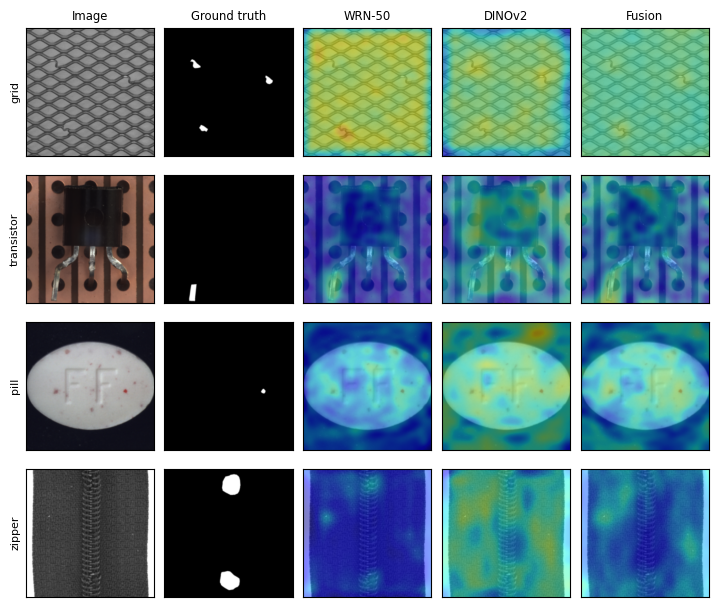

Saved /content/drive/MyDrive/DL_Project/report_assets/heatmaps.pdf


In [25]:
import sys, numpy as np, torch, matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from torch.utils.data import DataLoader, Subset
sys.path.insert(0, "/content/patchcore-inspection/src")
sys.path.insert(0, "/content/drive/MyDrive/DL_Project")
import oneshot_patchcore as op
from patchcore.datasets.mvtec import DatasetSplit, MVTecDataset

DATA, SEED, SIZE = "/content/mvtec", 0, 224
CATS = ["grid", "transistor", "pill", "zipper"]
MODELS = ["WRN-50", "DINOv2", "Fusion"]
device = torch.device("cuda")
dino = op.DinoFeatures("dinov2_vits14", [7, 11], device)
fusion = op.FusionFeatures("dinov2_vits14", [7, 11], SIZE, 0.1, 0.5, device)
show = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(SIZE)])

rows = []
for cls in CATS:
    train_full = MVTecDataset(DATA, classname=cls, resize=256, imagesize=SIZE,
                              split=DatasetSplit.TRAIN)
    test_ds = MVTecDataset(DATA, classname=cls, resize=256, imagesize=SIZE,
                           split=DatasetSplit.TEST)
    loader = DataLoader(test_ds, batch_size=8, shuffle=False, num_workers=2)
    # same single training image as seed 0 in the main experiments
    idx = np.random.RandomState(SEED).choice(len(train_full), size=1,
                                             replace=False).tolist()
    train_ds = Subset(train_full, idx)
    maps = {}
    op.set_seed(SEED)
    _, maps["WRN-50"], labels, masks, _ = op.run_wrn(train_ds, loader, SIZE,
                                                     0.1, device)
    op.set_seed(SEED)
    _, maps["DINOv2"], _, _, _ = op.run_bank(dino, train_ds, loader, SIZE,
                                             0.1, device)
    op.set_seed(SEED)
    _, maps["Fusion"], _, _, _ = op.run_bank(fusion, train_ds, loader, SIZE,
                                             0.1, device)
    i = int(np.argmax(np.asarray(labels) == 1))  # first defective test image
    img = show(Image.open(test_ds[i]["image_path"]).convert("RGB"))
    norm = {}
    for m in MODELS:  # scale each model's maps over the whole category
        a = np.asarray(maps[m])
        norm[m] = (a[i] - a.min()) / (a.max() - a.min() + 1e-8)
    rows.append((cls, img, np.asarray(masks)[i].squeeze(), norm))
    print(f"{cls}: done (test image #{i})")

plt.rcParams.update({"font.size": 7})
fig, axes = plt.subplots(len(rows), 5, figsize=(7.2, 1.55 * len(rows)))
titles = ["Image", "Ground truth"] + MODELS
for r, (cls, img, mask, norm) in enumerate(rows):
    axes[r, 0].imshow(img)
    axes[r, 0].set_ylabel(cls, fontsize=8)
    axes[r, 1].imshow(mask, cmap="gray")
    for c, m in enumerate(MODELS, start=2):
        axes[r, c].imshow(img)
        axes[r, c].imshow(norm[m], cmap="jet", alpha=0.5, vmin=0, vmax=1)
    for c in range(5):
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(titles[c])
plt.tight_layout()
out = "/content/drive/MyDrive/DL_Project/report_assets/heatmaps.pdf"
plt.savefig(out, dpi=200)
plt.show()
print("Saved", out)